# 02 - Model evaluation



In [ ]:
import sys
import time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# works whether the notebook runs from notebooks/ or from the repo root
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))   # so `import src...` and loading the saved models work

from src.models import Detector, BaselineDetector, NaiveBayesDetector, LogisticDetector
from src.evaluate import (Evaluator, make_cv_table, make_test_table,
                          plot_confusion_matrices, plot_model_comparison)

FIG = ROOT / 'figures'
FIG.mkdir(exist_ok=True)

train = pd.read_csv(ROOT / 'data' / 'split' / 'train.csv')
test = pd.read_csv(ROOT / 'data' / 'split' / 'test.csv')
print('train:', train.shape, ' test:', test.shape)

ev = Evaluator(train, test)
# default constructor values are Mirha's tuned settings (NB alpha=0.3, LR C=10)
detectors = {'baseline': BaselineDetector(),
             'naive_bayes': NaiveBayesDetector(),
             'logistic': LogisticDetector()}

train: (30964, 3)  test: (7741, 3)


## 1. 5-fold cross-validation (training set only)

Mean and standard deviation over 5 stratified folds (seed 42). The vectorizer is refit inside each fold. The baseline predicts the majority class (real), so its precision, recall and F1 for the fake class are 0, and its log-loss is very large because it outputs hard 0/1 probabilities.

In [2]:
cv_results = {}
for name, det in detectors.items():
    t0 = time.time()
    cv_results[name] = ev.cross_validate(det)
    print(f'{name}: done in {time.time() - t0:.0f}s')

cv_table = make_cv_table(cv_results)
display(cv_table)
cv_table.to_csv(FIG / 'metrics_cv.csv', encoding='utf-8-sig')

baseline: done in 12s
naive_bayes: done in 13s
logistic: done in 14s


,Accuracy,Precision (fake),Recall (fake),F1 (fake),Log-loss
Baseline,0.5377 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,16.6634 ± 0.0011
Naive Bayes,0.9370 ± 0.0033,0.9276 ± 0.0044,0.9368 ± 0.0048,0.9322 ± 0.0036,0.1638 ± 0.0058
Logistic regression,0.9463 ± 0.0030,0.9475 ± 0.0040,0.9358 ± 0.0058,0.9416 ± 0.0034,0.1499 ± 0.0037


## 2. Final test-set results

Uses the saved models from `models/`, which are the same models the app loads. Fake is the positive class.

In [3]:
loaded = {name: Detector.load(ROOT / 'models' / f'{name}.joblib') for name in detectors}
test_results = {name: ev.test_metrics(model) for name, model in loaded.items()}

test_table = make_test_table(test_results)
display(test_table)
test_table.to_csv(FIG / 'metrics_test.csv', encoding='utf-8-sig')

,Accuracy,Precision (fake),Recall (fake),F1 (fake),Log-loss
Baseline,0.5377,0.0000,0.0000,0.0000,16.6645
Naive Bayes,0.9398,0.9263,0.9450,0.9355,0.1617
Logistic regression,0.9455,0.9413,0.9408,0.9410,0.1456


## 3. Chart 3: confusion matrices (Naive Bayes and logistic regression)

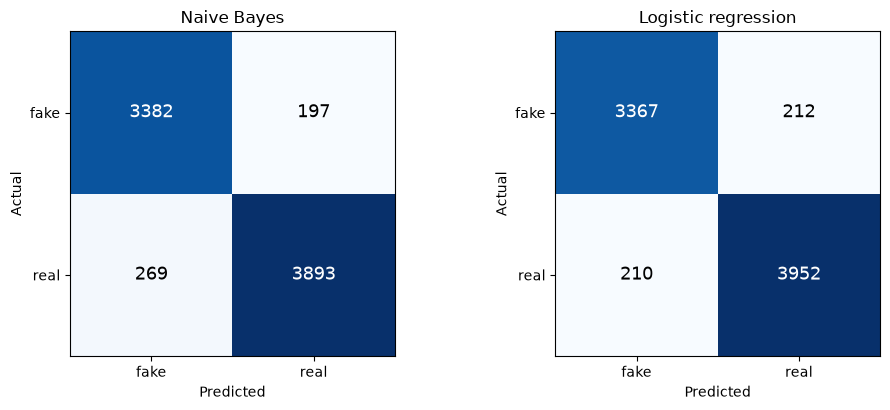

In [4]:
fig = plot_confusion_matrices(test_results)
fig.savefig(FIG / 'confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Chart 4: model comparison (baseline included)

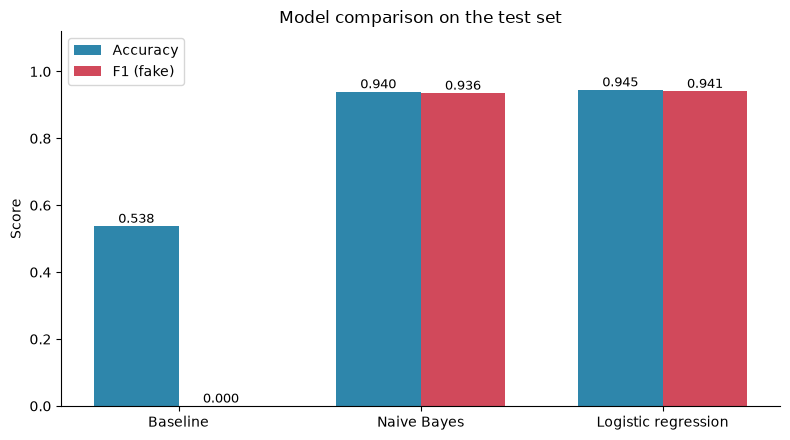

In [5]:
fig = plot_model_comparison(test_results)
fig.savefig(FIG / 'model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Failure cases

The logistic regression's most confident mistakes

In [6]:
lr = loaded['logistic']
pred = lr.predict(test['title'])
conf = lr.predict_proba(test['title']).max(axis=1)
wrong = test.assign(predicted=pred, confidence=conf.round(3))[pred != test['label'].values]
print(f'{len(wrong)} mistakes out of {len(test)} test headlines')
pd.set_option('display.max_colwidth', 120)
display(wrong.sort_values('confidence', ascending=False).head(15)[['title', 'label', 'predicted', 'confidence']])

422 mistakes out of 7741 test headlines


,title,label,predicted,confidence
7331,iraqi pm rebuffs us decree that foreign shia militias should leave country,fake,real,0.997
6916,obama not so secret admirer donald trump,real,fake,0.996
2071,joe the plumber praises trump cites his beautiful women,real,fake,0.995
4290,eu leaders pledge extra 1 billion in aid to refugees slovakia will take eu to court over forced refugee quotas,fake,real,0.994
3625,struggling republican bush brings out the big gun his mom,real,fake,0.993
3912,forsaken sultan erdogan isolated ahead trump meeting in washington,fake,real,0.992
6741,at least 14 us coalition military officers captured by syrian special forces in east aleppo bunker,fake,real,0.987
1806,obama on trump victory we are now all rooting for his success,real,fake,0.987
4479,palestinian protesters attack us embassy in lebanon,fake,real,0.987
127,why should americans trust you trump asked,real,fake,0.986
